## 1. Setup

### Install Extra Libraries

In [3]:
!pip install imagehash

In [48]:
import os, random, shutil, hashlib
from collections import Counter, defaultdict
import imagehash
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers , models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from tensorflow.keras.applications import EfficientNetB2, ResNet50, MobileNetV2
from tensorflow.keras.applications.efficientnet import preprocess_input as effnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess


SEED = 42
random.seed(SEED)
np.random.seed(SEED)



## 2. Data Loading

### 2.1 Download the Dataset from Kaggle

In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("salmansajid05/oral-diseases")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'oral-diseases' dataset.
Path to dataset files: /kaggle/input/oral-diseases


### 2.2 Inspect the Folder Structure

In [6]:
for cls in ["Calculus", "Data caries", "Gingivitis", "hypodontia", "Mouth Ulcer", "Tooth Discoloration"]:
    print("\n==", cls)
    for root, dirs, files in os.walk(os.path.join(path, cls)):
        imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        if imgs:
            print(root.replace(path, ""), "->", len(imgs), "images")


== Calculus
/Calculus/Calculus -> 1296 images

== Data caries
/Data caries/Data caries/caries orignal data set/done -> 219 images
/Data caries/Data caries/caries augmented data set/preview -> 2382 images

== Gingivitis
/Gingivitis/Gingivitis -> 2349 images

== hypodontia
/hypodontia/hypodontia -> 1251 images

== Mouth Ulcer
/Mouth Ulcer/Mouth Ulcer/Mouth_Ulcer_augmented_DataSet/preview -> 2541 images
/Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset -> 265 images

== Tooth Discoloration
/Tooth Discoloration/Tooth Discoloration /Tooth_discoloration_augmented_dataser/preview -> 1834 images
/Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset -> 183 images


## 3. Data Cleaning

### 3.1 Select the Original Image Folders

In [7]:
# Only the ORIGINAL images are used. The augmented folders and the YOLO folder are ignored.
ROOT = path

class_dirs = {
    "Caries": f"{ROOT}/Data caries/Data caries/caries orignal data set/done",
    "Mouth Ulcer": f"{ROOT}/Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset",
    "Tooth Discoloration": f"{ROOT}/Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset",
    "Calculus": f"{ROOT}/Calculus/Calculus",
    "Gingivitis": f"{ROOT}/Gingivitis/Gingivitis",
    "hypodontia": f"{ROOT}/hypodontia/hypodontia",
}

for cls, folder in class_dirs.items():
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Folder not found for {cls}: {folder}")

### 3.2 Remove Exact Duplicates and Cross-Class Conflicts

In [8]:
def file_hash(file_path):
    """Return a SHA-256 hash of the file contents, reading in chunks."""
    digest = hashlib.sha256()
    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


# Map each exact image hash to all (class, path) occurrences.
hash_map = defaultdict(list)

for cls, folder in class_dirs.items():
    for root, _, files in os.walk(folder):
        for filename in files:
            if filename.lower().endswith(EXTS):
                image_path = os.path.join(root, filename)
                hash_map[file_hash(image_path)].append((cls, image_path))

# Exclude exact duplicates that appear under different class labels.
conflict_hashes = {
    image_hash
    for image_hash, items in hash_map.items()
    if len({cls for cls, _ in items}) > 1
}

exact_conflicts = []
paths, labels = [], []

for image_hash, items in hash_map.items():
    classes_for_hash = sorted({cls for cls, _ in items})

    if image_hash in conflict_hashes:
        for cls, image_path in items:
            exact_conflicts.append({
                "hash": image_hash,
                "class": cls,
                "path": image_path,
                "classes_for_same_image": ", ".join(classes_for_hash),
            })
        continue

    # Exact duplicates within one class collapse to one representative.
    cls, image_path = items[0]
    paths.append(image_path)
    labels.append(cls)

pd.DataFrame(exact_conflicts).to_csv(
    "exact_cross_class_conflicts.csv", index=False
)

print("Total image files found:", sum(len(items) for items in hash_map.values()))
print("Unique exact-image hashes:", len(hash_map))
print("Exact cross-class conflict groups:", len(conflict_hashes))
print("Images excluded due to cross-class conflicts:", len(exact_conflicts))
print("Images retained after exact deduplication:", len(paths))
print("Class distribution:", Counter(labels))


Total image files found: 5563
Unique exact-image hashes: 3899
Exact cross-class conflict groups: 392
Images excluded due to cross-class conflicts: 1510
Images retained after exact deduplication: 3507
Class distribution: Counter({'Gingivitis': 1236, 'hypodontia': 1215, 'Calculus': 449, 'Mouth Ulcer': 243, 'Caries': 191, 'Tooth Discoloration': 173})


### 3.3 Group Near-Duplicate Images (Perceptual Hash)

In [9]:
def bits(img):
    """Return a flattened 64-bit perceptual hash."""
    return imagehash.phash(img, hash_size=8).hash.flatten()


THRESH = 5  # Initial review threshold; not proof that two images are duplicates.

# Compute pHash for each image and its horizontal mirror.
hash_rows, hash_rows_flip, valid_indices, unreadable = [], [], [], []

for i, image_path in enumerate(paths):
    try:
        with Image.open(image_path) as im:
            img = im.convert("RGB")
        hash_rows.append(bits(img))
        hash_rows_flip.append(bits(ImageOps.mirror(img)))
        valid_indices.append(i)
    except Exception as exc:
        unreadable.append({"path": image_path, "error": str(exc)})

paths = [paths[i] for i in valid_indices]
labels = [labels[i] for i in valid_indices]
H = np.asarray(hash_rows, dtype=bool)
H_flip = np.asarray(hash_rows_flip, dtype=bool)

pd.DataFrame(unreadable).to_csv("unreadable_images.csv", index=False)
print("Unreadable images skipped:", len(unreadable))

# Greedy representative grouping. Compare both orientations of the query and
# both orientations of each representative to account for horizontal flips.
n_images = len(paths)
rep_bits = np.zeros((n_images, 64), dtype=bool)
rep_bits_flip = np.zeros((n_images, 64), dtype=bool)
groups = np.empty(n_images, dtype=int)
n_reps = 0

for i in range(n_images):
    if n_reps:
        distances = np.minimum.reduce([
            (rep_bits[:n_reps] != H[i]).sum(axis=1),
            (rep_bits[:n_reps] != H_flip[i]).sum(axis=1),
            (rep_bits_flip[:n_reps] != H[i]).sum(axis=1),
            (rep_bits_flip[:n_reps] != H_flip[i]).sum(axis=1),
        ])
        nearest = int(distances.argmin())
        group_id = nearest if distances[nearest] <= THRESH else -1
    else:
        group_id = -1

    if group_id == -1:
        group_id = n_reps
        rep_bits[n_reps] = H[i]
        rep_bits_flip[n_reps] = H_flip[i]
        n_reps += 1

    groups[i] = group_id

# Retain hashes for a later optional audit if needed.
bits_by_path = {image_path: H[i] for i, image_path in enumerate(paths)}
bits_flip_by_path = {image_path: H_flip[i] for i, image_path in enumerate(paths)}

print("Readable images:", len(paths))
print("Near-duplicate groups:", len(set(groups)))


Unreadable images skipped: 0
Readable images: 3507
Near-duplicate groups: 2220


### 3.4 Visual Check of the Groups

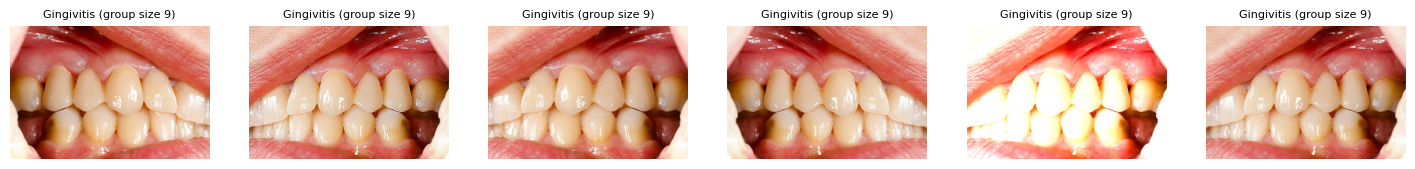

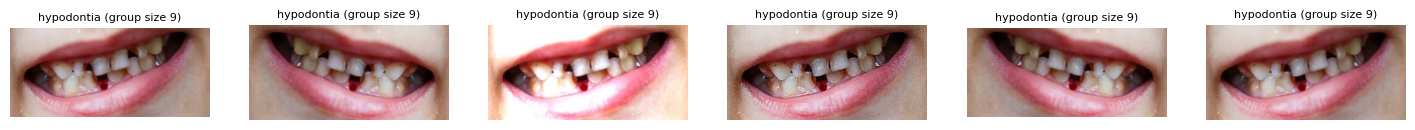

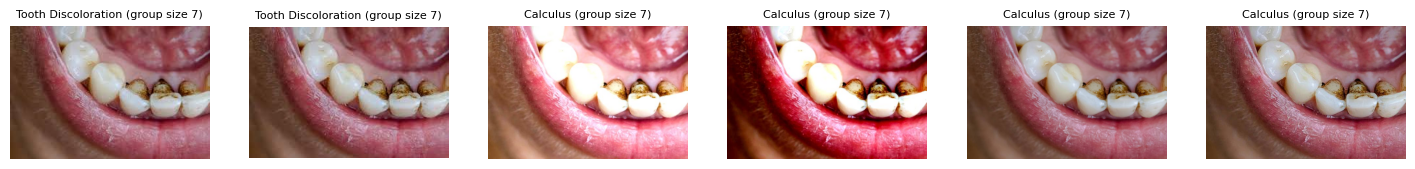

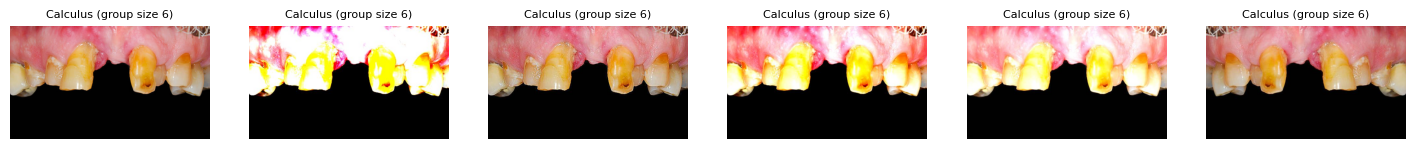

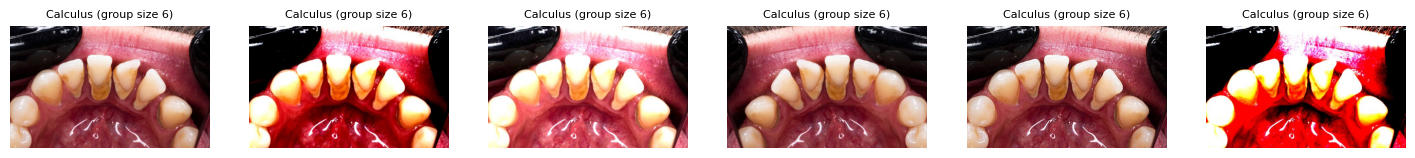

In [10]:
# Look at the biggest groups BEFORE removing anything, to check that THRESH is reasonable
sizes = Counter(groups)

for g, n in sizes.most_common(5):
    idx = np.where(groups == g)[0][:6]
    fig, axes = plt.subplots(1, len(idx), figsize=(3 * len(idx), 3))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, idx):
        ax.imshow(Image.open(paths[i]))
        ax.set_title(f"{labels[i]} (group size {n})", fontsize=8)
        ax.axis("off")
    plt.show()

### 3.5 Remove Near-Duplicates and Exclude Label Conflicts

In [11]:
# Identify pHash groups that contain more than one class label.
group_labels = defaultdict(set)
for group_id, label in zip(groups, labels):
    group_labels[group_id].add(label)

bad_groups = {
    group_id
    for group_id, class_set in group_labels.items()
    if len(class_set) > 1
}

# Save every image in conflicting groups for manual label review.
conflicting_group_rows = []
for i, group_id in enumerate(groups):
    if group_id in bad_groups:
        conflicting_group_rows.append({
            "group_id": int(group_id),
            "class": labels[i],
            "path": paths[i],
            "classes_in_group": ", ".join(sorted(group_labels[group_id])),
        })

pd.DataFrame(conflicting_group_rows).to_csv(
    "near_duplicate_cross_class_conflicts.csv", index=False
)

print("Near-duplicate groups with conflicting labels:", len(bad_groups))
print("Images in conflicting groups:", len(conflicting_group_rows))

# Keep one representative per consistent pHash group.
# This also removes near-duplicates within the same class.
keep_indices = []
seen_groups = set()

for i, group_id in enumerate(groups):
    if group_id in bad_groups or group_id in seen_groups:
        continue
    keep_indices.append(i)
    seen_groups.add(group_id)

before_count = len(paths)
paths = [paths[i] for i in keep_indices]
labels = [labels[i] for i in keep_indices]
groups = groups[keep_indices]

print("Images before pHash cleaning:", before_count)
print("Images after pHash cleaning:", len(paths))
print("Images removed:", before_count - len(paths))
print("Final class distribution:", Counter(labels))


Near-duplicate groups with conflicting labels: 1
Images in conflicting groups: 7
Images before pHash cleaning: 3507
Images after pHash cleaning: 2219
Images removed: 1288
Final class distribution: Counter({'Gingivitis': 702, 'hypodontia': 686, 'Calculus': 261, 'Mouth Ulcer': 224, 'Caries': 181, 'Tooth Discoloration': 165})


## 4. Data Splitting

### 4.1 Stratified Split: 70% Train / 15% Val / 15% Test

In [12]:
class_counts = Counter(labels)
MIN_PER_CLASS = 10

if len(class_counts) != len(class_dirs):
    raise ValueError(
        f"Expected {len(class_dirs)} classes, found {len(class_counts)}: {class_counts}"
    )

if min(class_counts.values()) < MIN_PER_CLASS:
    raise ValueError(
        f"Each class needs at least {MIN_PER_CLASS} images after cleaning. "
        f"Counts: {class_counts}"
    )

# 70% train, 30% temporary.
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels,
)

# Split the temporary set equally into validation and test.
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels,
)

print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(test_paths))

for split_name, split_labels in [
    ("train", train_labels),
    ("validation", val_labels),
    ("test", test_labels),
]:
    print(f"\n{split_name.title()} distribution:")
    print(Counter(split_labels))


Train: 1553
Validation: 333
Test: 333

Train distribution:
Counter({'Gingivitis': 491, 'hypodontia': 480, 'Calculus': 183, 'Mouth Ulcer': 157, 'Caries': 127, 'Tooth Discoloration': 115})

Validation distribution:
Counter({'Gingivitis': 105, 'hypodontia': 103, 'Calculus': 39, 'Mouth Ulcer': 34, 'Caries': 27, 'Tooth Discoloration': 25})

Test distribution:
Counter({'Gingivitis': 106, 'hypodontia': 103, 'Calculus': 39, 'Mouth Ulcer': 33, 'Caries': 27, 'Tooth Discoloration': 25})


### 4.2 Save the Split to Disk

In [13]:
# Use a persistent output location when running on Colab; otherwise use a local folder.
DATASET = "/content/dataset" if os.path.isdir("/content") else "dataset"

# Recreate the output directory to prevent stale files from previous runs.
if os.path.exists(DATASET):
    shutil.rmtree(DATASET)

splits = {
    "train": (train_paths, train_labels),
    "val": (val_paths, val_labels),
    "test": (test_paths, test_labels),
}

for split_name, (split_paths, split_labels) in splits.items():
    for cls in class_dirs:
        os.makedirs(os.path.join(DATASET, split_name, cls), exist_ok=True)

    for i, (source_path, cls) in enumerate(zip(split_paths, split_labels)):
        extension = os.path.splitext(source_path)[1].lower()
        destination = os.path.join(
            DATASET, split_name, cls, f"{i:06d}{extension}"
        )
        shutil.copy2(source_path, destination)

print("Dataset saved to:", DATASET)


Dataset saved to: /content/dataset


## 5. Split Validation

### 5.1 Exact-Duplicate Check Between Splits

In [14]:
split_hashes = {}

for split_name in ["train", "val", "test"]:
    current_hashes = set()
    for cls in class_dirs:
        folder = os.path.join(DATASET, split_name, cls)
        for f in os.listdir(folder):
            if f.lower().endswith(EXTS):
                current_hashes.add(file_hash(os.path.join(folder, f)))
    split_hashes[split_name] = current_hashes

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = split_hashes[a] & split_hashes[b]
    print(f"{a} vs {b}: {len(overlap)} exact duplicates")
    assert len(overlap) == 0, f"Duplicate images found between {a} and {b}"

train vs val: 0 exact duplicates
train vs test: 0 exact duplicates
val vs test: 0 exact duplicates


### 5.2 Near-Duplicate Check with a Looser Threshold

val: 81 of 333 images have a train image within distance 10


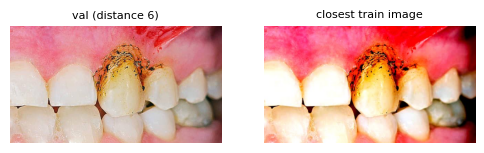

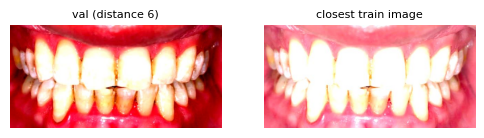

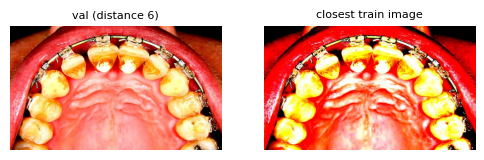

test: 85 of 333 images have a train image within distance 10


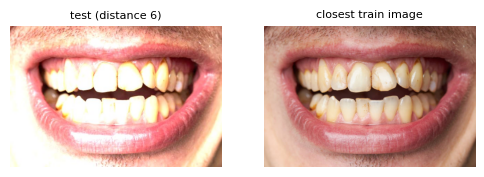

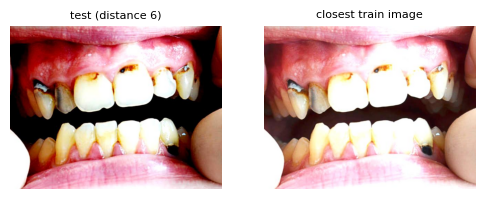

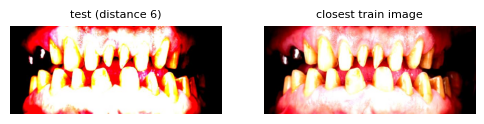

In [15]:
# Grouping used THRESH, so no pair below it can remain. Here we look for borderline pairs
# (distance <= AUDIT_THRESH) between train and the val/test images.
AUDIT_THRESH = 10

def nearest_train(query_paths):
    ref = np.array([bits_by_path[p] for p in train_paths])
    rows = []
    for p in query_paths:
        d = np.minimum(
            (ref != bits_by_path[p]).sum(axis=1),
            (ref != bits_flip_by_path[p]).sum(axis=1),
        )
        j = int(d.argmin())
        rows.append((int(d[j]), p, train_paths[j]))
    return sorted(rows)

for name, q in [("val", val_paths), ("test", test_paths)]:
    rows = nearest_train(q)
    close = [r for r in rows if r[0] <= AUDIT_THRESH]
    print(f"{name}: {len(close)} of {len(rows)} images have a train image within distance {AUDIT_THRESH}")

    for dist, p_q, p_t in close[:3]:
        fig, axes = plt.subplots(1, 2, figsize=(6, 3))
        axes[0].imshow(Image.open(p_q)); axes[0].set_title(f"{name} (distance {dist})", fontsize=8)
        axes[1].imshow(Image.open(p_t)); axes[1].set_title("closest train image", fontsize=8)
        for ax in axes:
            ax.axis("off")
        plt.show()

### 5.3 Class Distribution per Split

class                    train     val    test
Caries                     127      27      27
Mouth Ulcer                157      34      33
Tooth Discoloration        115      25      25
Calculus                   183      39      39
Gingivitis                 491     105     106
hypodontia                 480     103     103


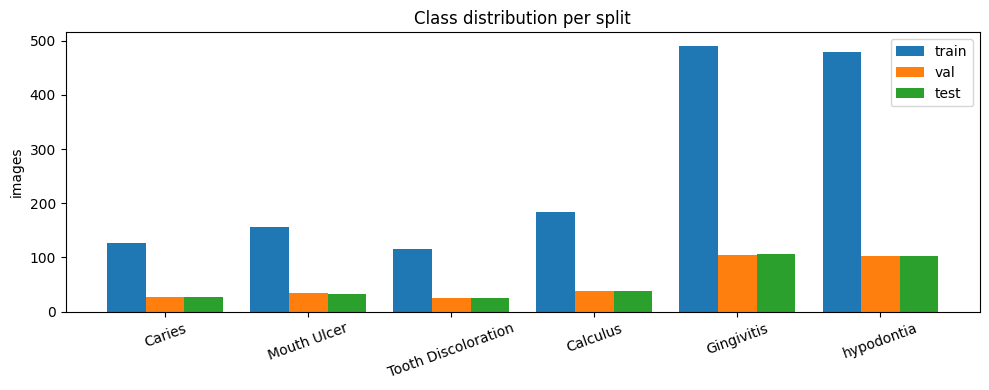

In [16]:
classes = list(class_dirs)
split_label_lists = {"train": train_labels, "val": val_labels, "test": test_labels}

print(f"{'class':22s}" + "".join(f"{s:>8s}" for s in split_label_lists))
for c in classes:
    print(f"{c:22s}" + "".join(f"{Counter(l)[c]:>8d}" for l in split_label_lists.values()))

x = np.arange(len(classes))
width = 0.27
plt.figure(figsize=(10, 4))
for k, (s, l) in enumerate(split_label_lists.items()):
    plt.bar(x + (k - 1) * width, [Counter(l)[c] for c in classes], width, label=s)
plt.xticks(x, classes, rotation=20)
plt.ylabel("images")
plt.title("Class distribution per split")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Data Pipeline

### 6.1 Load the Datasets with image_dataset_from_directory

In [17]:
IMG_SIZE = (224, 224)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH,
    shuffle=True,
    seed=SEED,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET, "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH,
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH,
    shuffle=False,
)

class_names = train_ds.class_names   # must be captured before any .map()
print(class_names)
print("Number of classes:", len(class_names))

Found 1553 files belonging to 6 classes.


Found 333 files belonging to 6 classes.
Found 333 files belonging to 6 classes.
['Calculus', 'Caries', 'Gingivitis', 'Mouth Ulcer', 'Tooth Discoloration', 'hypodontia']
Number of classes: 6


### 6.2 Optimize Performance (Cache and Prefetch)

In [18]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)


### 6.3 Visualize a Sample Batch

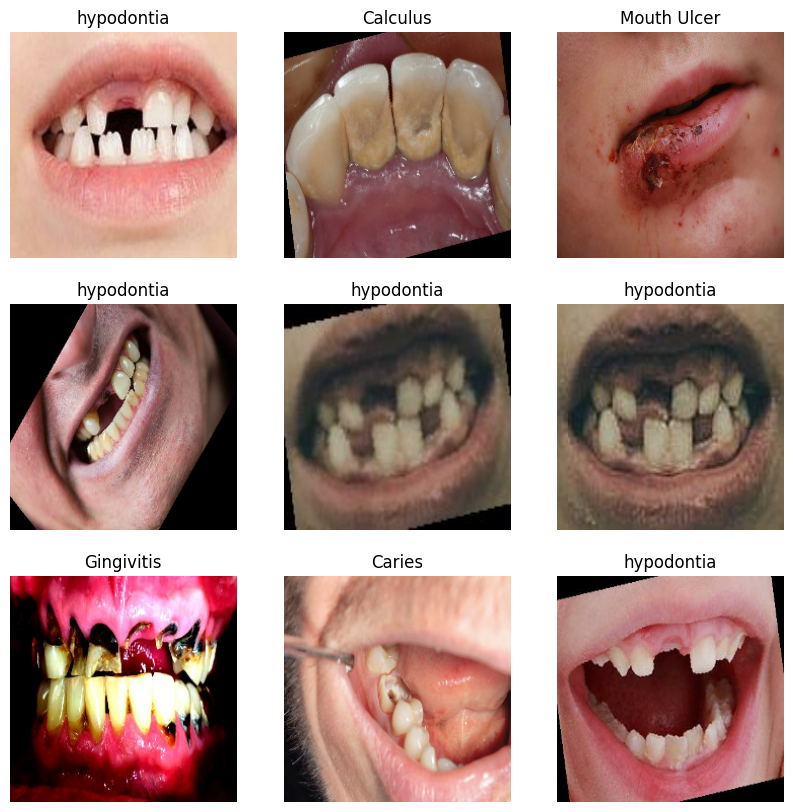

In [19]:
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

## 7. Custom CNN Model

### 7.1 Data Augmentation Layers

In [20]:
Augmentation = tf.keras.Sequential(
    [
        layers.RandomRotation(factor=0.08),
        layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
        layers.RandomFlip(mode="horizontal"),
        layers.RandomContrast(factor=0.05),
    ],
    name="img_augmentation",
)

### 7.2 Visualize Augmented Images

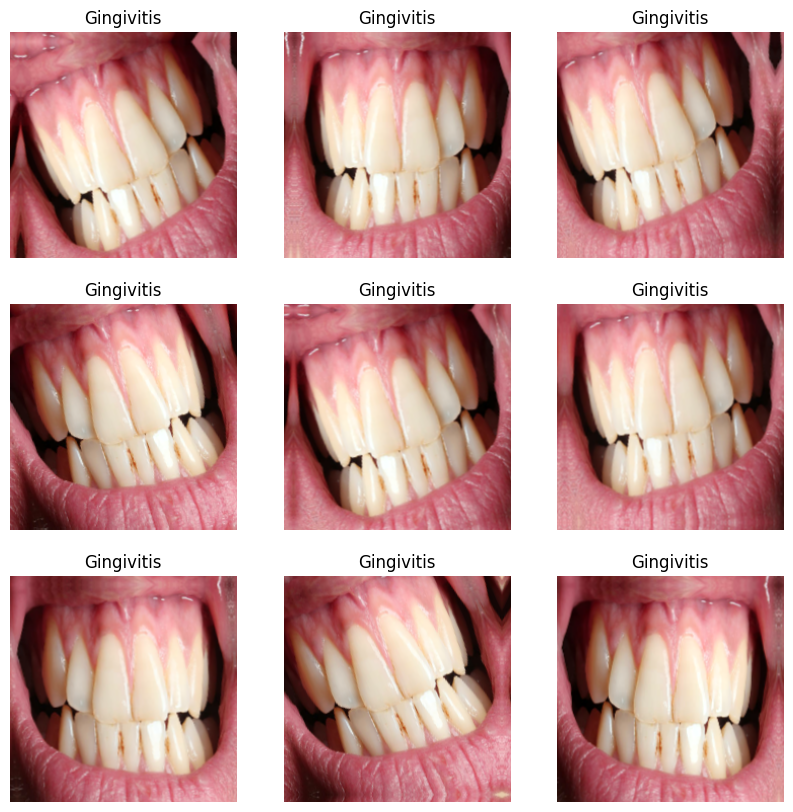

In [21]:
plt.figure(figsize=(10,10))

for image,labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3,3,i+1)
        aug_img = Augmentation(tf.expand_dims(image[0],axis=0))
        plt.imshow(aug_img[0].numpy().astype('uint8'))
        plt.title(class_names[labels[0]])
        plt.axis('off')

### 7.3 Training Callbacks

In [22]:
early_stop = EarlyStopping(monitor="val_accuracy", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_accuracy", factor=0.5, patience=3, min_lr=1e-6)
model_ckpt = ModelCheckpoint("cnn_model.keras", save_best_only=True, monitor="val_accuracy", mode="max")

callbacks = [early_stop, model_ckpt, reduce_lr]

### 7.4 Build the CNN Architecture

In [23]:
NUM_CLASSES = len(class_names)

cnn_model = keras.Sequential(
    [
        keras.Input(shape=(224, 224, 3), name="input_image"),
        layers.Rescaling(1.0 / 255),
        Augmentation,

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(),

        layers.Conv2D(256, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.5),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ],
    name="custom_cnn",
)

cnn_model.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ img_augmentation (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,006 (1.62 MB)

 Trainable params: 423,046 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

### 7.5 Compile the Model

In [24]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

### 7.6 Compute Class Weights

In [25]:
y_train_idx = np.array([class_names.index(l) for l in train_labels])

weights = compute_class_weight(
    "balanced",
    classes=np.arange(len(class_names)),
    y=y_train_idx,
)
class_weights = dict(enumerate(weights))
print(class_weights)

{0: np.float64(1.4143897996357013), 1: np.float64(2.038057742782152), 2: np.float64(0.5271554650373388), 3: np.float64(1.648619957537155), 4: np.float64(2.2507246376811594), 5: np.float64(0.5392361111111111)}


### 7.7 Train the Model

In [26]:
EPOCHS = 50

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,   # from the split stage
    callbacks=callbacks,
)

Epoch 1/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 17s 174ms/step - accuracy: 0.2769 - loss: 1.8846 - val_accuracy: 0.2703 - val_loss: 1.8139 - learning_rate: 0.0010
Epoch 2/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 126ms/step - accuracy: 0.3831 - loss: 1.5069 - val_accuracy: 0.4895 - val_loss: 1.3313 - learning_rate: 0.0010
Epoch 3/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 124ms/step - accuracy: 0.4462 - loss: 1.4021 - val_accuracy: 0.4234 - val_loss: 1.3681 - learning_rate: 0.0010
Epoch 4/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 126ms/step - accuracy: 0.5016 - loss: 1.2960 - val_accuracy: 0.5766 - val_loss: 1.0683 - learning_rate: 0.0010
Epoch 5/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 124ms/step - accuracy: 0.5184 - loss: 1.2428 - val_accuracy: 0.3453 - val_loss: 1.7150 - learning_rate: 0.0010
Epoch 6/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 125ms/step - accuracy: 0.5428 - loss: 1.2301 - val_accuracy: 0.4685 - val_loss: 1.3427 - learning_rate: 0.0010
Epoch 7/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - accuracy: 0.5596 - loss: 1.1570 -

## 8. Evaluate the Custom CNN

### 8.1 Training History Curves

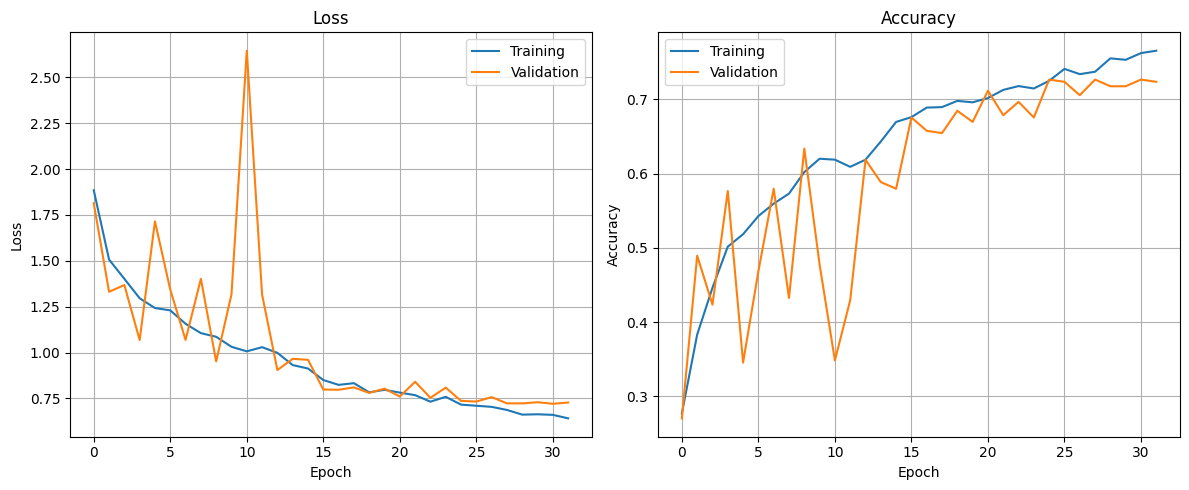

In [32]:
plt.figure(figsize=(12,5))

# Loss
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 8.2 Evaluation on the Test Set

In [28]:
test_loss, test_acc = cnn_model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7147 - loss: 0.7722
Test accuracy: 0.7147
Test loss: 0.7722


### 8.3 Classification Report and Confusion Matrix

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step
                     precision    recall  f1-score   support

           Calculus       0.52      0.90      0.66        39
             Caries       0.44      0.41      0.42        27
         Gingivitis       0.86      0.67      0.75       106
        Mouth Ulcer       0.72      0.70      0.71        33
Tooth Discoloration       0.47      0.72      0.57        25
         hypodontia       0.91      0.78      0.84       103

           accuracy                           0.71       333
          macro avg       0.65      0.69      0.66       333
       weighted avg       0.76      0.71      0.72       333



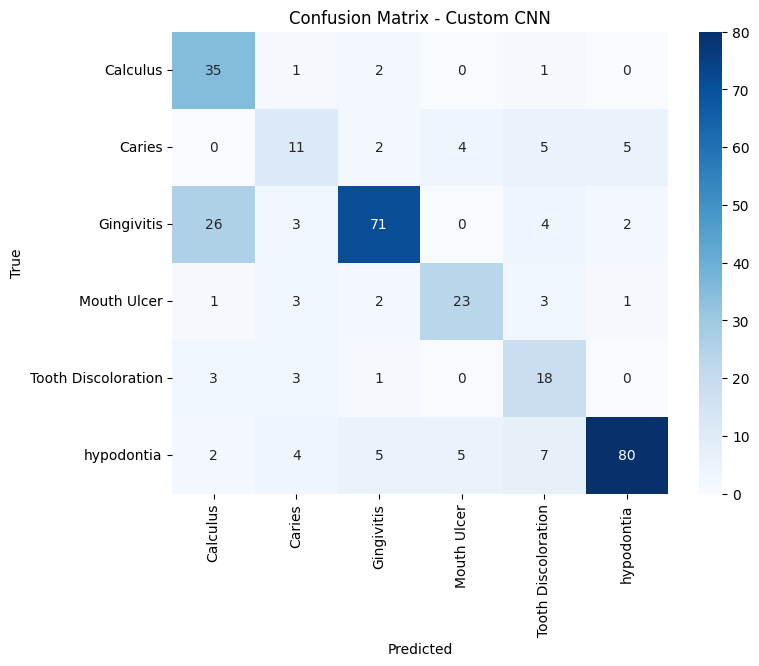

In [29]:
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_pred_probs = cnn_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Custom CNN")
plt.show()

## 9. Pretrained Model 1: EfficientNetB2

### 9.1 Build the Model (Feature Extraction)

In [ ]:
base_model_effnet = EfficientNetB2(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
    pooling="avg",
)
base_model_effnet.trainable = False

inputs = keras.Input(shape=(224, 224, 3), name="input_image")
x = Augmentation(inputs)
x = layers.Lambda(effnet_preprocess, name="effnet_preprocess")(x)
x = base_model_effnet(x, training=False)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

effnet_model = keras.Model(inputs, outputs, name="efficientnetb2_transfer")
effnet_model.summary()

31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ img_augmentation (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ effnet_preprocess (Lambda)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb2 (Functional)     │ (None, 1408)           │     7,768,569 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       180,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,949,695 (30.33 MB)

 Trainable params: 181,126 (707.52 KB)

 Non-trainable params: 7,768,569 (29.63 MB)

### 9.2 Compile the Model

In [35]:
effnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

### 9.3 Training Callbacks

In [36]:
early_stop_effnet = EarlyStopping(monitor="val_accuracy", patience=7, restore_best_weights=True)
reduce_lr_effnet = ReduceLROnPlateau(monitor="val_accuracy", factor=0.5, patience=3, min_lr=1e-6)
ckpt_effnet = ModelCheckpoint("efficientnetb2_model.keras", save_best_only=True, monitor="val_accuracy", mode="max")

callbacks_effnet = [early_stop_effnet, ckpt_effnet, reduce_lr_effnet]

### 9.4 Train the Model

In [37]:
EPOCHS_TL = 30

history_effnet = effnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_TL,
    class_weight=class_weights,
    callbacks=callbacks_effnet,
)

Epoch 1/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 24s 241ms/step - accuracy: 0.4862 - loss: 1.3945 - val_accuracy: 0.6667 - val_loss: 1.0099 - learning_rate: 0.0010
Epoch 2/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 146ms/step - accuracy: 0.6458 - loss: 0.9652 - val_accuracy: 0.7508 - val_loss: 0.7752 - learning_rate: 0.0010
Epoch 3/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 147ms/step - accuracy: 0.6941 - loss: 0.8129 - val_accuracy: 0.7718 - val_loss: 0.6879 - learning_rate: 0.0010
Epoch 4/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 125ms/step - accuracy: 0.7212 - loss: 0.7320 - val_accuracy: 0.7658 - val_loss: 0.6995 - learning_rate: 0.0010
Epoch 5/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 149ms/step - accuracy: 0.7579 - loss: 0.6199 - val_accuracy: 0.7928 - val_loss: 0.6255 - learning_rate: 0.0010
Epoch 6/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 127ms/step - accuracy: 0.7598 - loss: 0.6114 - val_accuracy: 0.7868 - val_loss: 0.6249 - learning_rate: 0.0010
Epoch 7/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 152ms/step - accuracy: 0.7939 - loss: 0.5492 -

### 9.5 Training History Curves

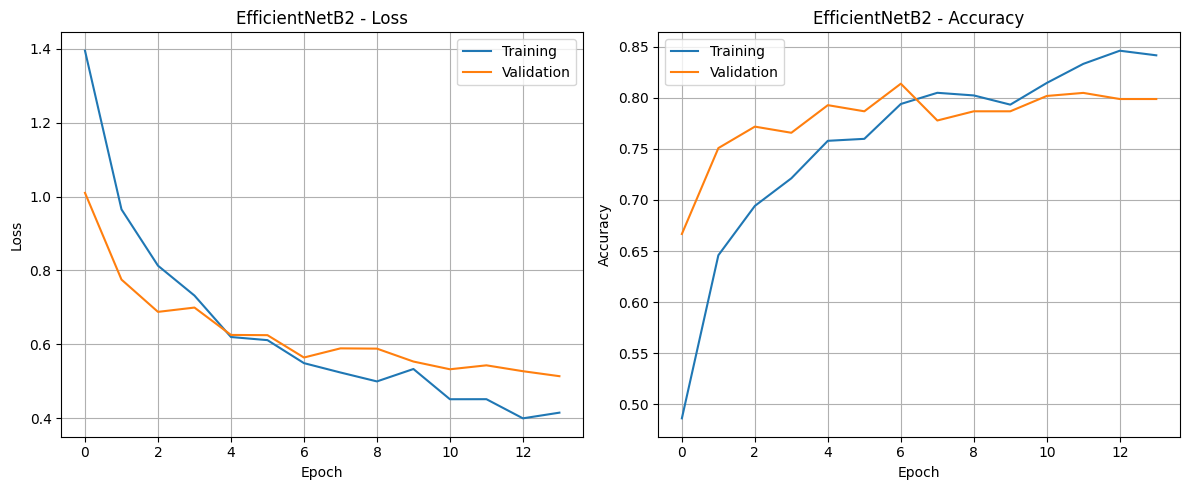

In [38]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_effnet.history['loss'], label='Training')
plt.plot(history_effnet.history['val_loss'], label='Validation')
plt.title('EfficientNetB2 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_effnet.history['accuracy'], label='Training')
plt.plot(history_effnet.history['val_accuracy'], label='Validation')
plt.title('EfficientNetB2 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 9.6 Evaluation on the Test Set

In [39]:
test_loss_effnet, test_acc_effnet = effnet_model.evaluate(test_ds)
print(f"EfficientNetB2 - Test accuracy: {test_acc_effnet:.4f}")
print(f"EfficientNetB2 - Test loss: {test_loss_effnet:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step - accuracy: 0.7958 - loss: 0.6104
EfficientNetB2 - Test accuracy: 0.7958
EfficientNetB2 - Test loss: 0.6104


### 9.7 Classification Report and Confusion Matrix

11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 367ms/step
                     precision    recall  f1-score   support

           Calculus       0.79      0.67      0.72        39
             Caries       0.57      0.48      0.52        27
         Gingivitis       0.77      0.90      0.83       106
        Mouth Ulcer       0.83      0.88      0.85        33
Tooth Discoloration       0.55      0.64      0.59        25
         hypodontia       0.96      0.83      0.89       103

           accuracy                           0.80       333
          macro avg       0.74      0.73      0.73       333
       weighted avg       0.80      0.80      0.80       333



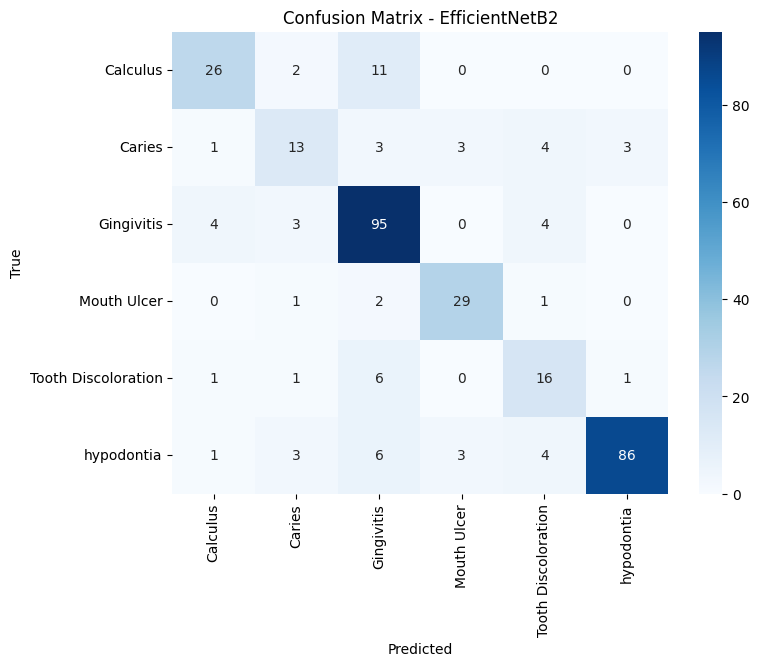

In [40]:
y_pred_probs_effnet = effnet_model.predict(test_ds)
y_pred_effnet = np.argmax(y_pred_probs_effnet, axis=1)

print(classification_report(y_true, y_pred_effnet, target_names=class_names))

cm_effnet = confusion_matrix(y_true, y_pred_effnet)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_effnet, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - EfficientNetB2")
plt.show()

## 10. Pretrained Model 2: ResNet50

### 10.1 Build the Model (Feature Extraction)

In [41]:
base_model_resnet = ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
    pooling="avg",
)
base_model_resnet.trainable = False

inputs = keras.Input(shape=(224, 224, 3), name="input_image")
x = Augmentation(inputs)
x = layers.Lambda(resnet_preprocess, name="resnet_preprocess")(x)
x = base_model_resnet(x, training=False)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

resnet_model = keras.Model(inputs, outputs, name="resnet50_transfer")
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "resnet50_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ img_augmentation (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocess (Lambda)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,758 (90.98 MB)

 Trainable params: 263,046 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

### 10.2 Compile the Model

In [42]:
resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

### 10.3 Training Callbacks

In [43]:
early_stop_resnet = EarlyStopping(monitor="val_accuracy", patience=7, restore_best_weights=True)
reduce_lr_resnet = ReduceLROnPlateau(monitor="val_accuracy", factor=0.5, patience=3, min_lr=1e-6)
ckpt_resnet = ModelCheckpoint("resnet50_model.keras", save_best_only=True, monitor="val_accuracy", mode="max")

callbacks_resnet = [early_stop_resnet, ckpt_resnet, reduce_lr_resnet]

### 10.4 Train the Model

In [44]:
history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_TL,
    class_weight=class_weights,
    callbacks=callbacks_resnet,
)

Epoch 1/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 19s 254ms/step - accuracy: 0.4829 - loss: 1.5119 - val_accuracy: 0.6456 - val_loss: 0.9614 - learning_rate: 0.0010
Epoch 2/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 9s 192ms/step - accuracy: 0.6426 - loss: 0.9697 - val_accuracy: 0.6667 - val_loss: 0.8542 - learning_rate: 0.0010
Epoch 3/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 9s 193ms/step - accuracy: 0.7012 - loss: 0.8182 - val_accuracy: 0.6787 - val_loss: 0.8052 - learning_rate: 0.0010
Epoch 4/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 10s 197ms/step - accuracy: 0.7276 - loss: 0.7609 - val_accuracy: 0.7658 - val_loss: 0.6228 - learning_rate: 0.0010
Epoch 5/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 9s 181ms/step - accuracy: 0.7592 - loss: 0.6914 - val_accuracy: 0.7327 - val_loss: 0.6840 - learning_rate: 0.0010
Epoch 6/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 9s 184ms/step - accuracy: 0.7817 - loss: 0.5983 - val_accuracy: 0.7568 - val_loss: 0.6188 - learning_rate: 0.0010
Epoch 7/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 9s 183ms/step - accuracy: 0.7733 - loss: 0.6213 

### 10.5 Training History Curves

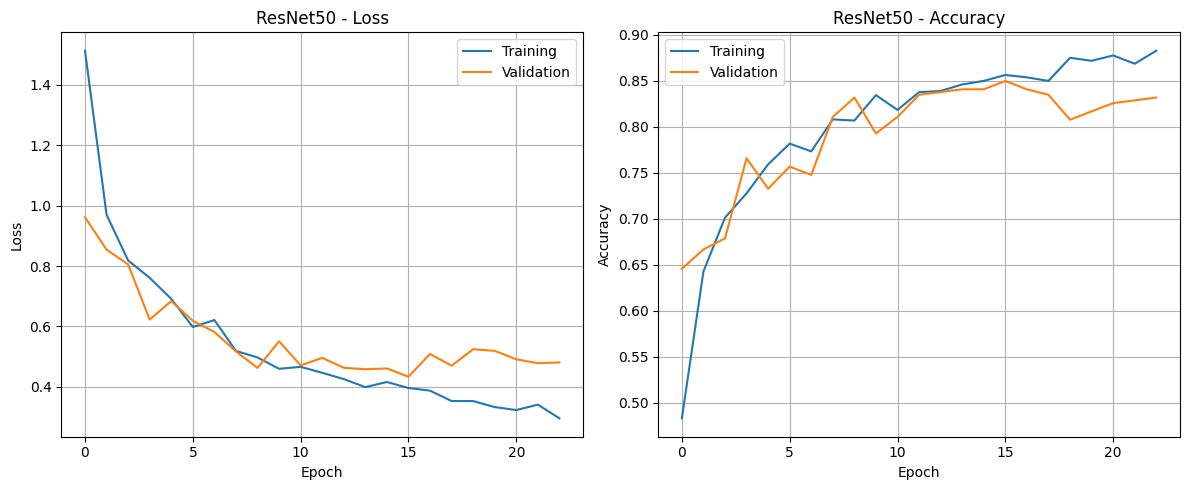

In [45]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_resnet.history['loss'], label='Training')
plt.plot(history_resnet.history['val_loss'], label='Validation')
plt.title('ResNet50 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_resnet.history['accuracy'], label='Training')
plt.plot(history_resnet.history['val_accuracy'], label='Validation')
plt.title('ResNet50 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 10.6 Evaluation on the Test Set

In [46]:
test_loss_resnet, test_acc_resnet = resnet_model.evaluate(test_ds)
print(f"ResNet50 - Test accuracy: {test_acc_resnet:.4f}")
print(f"ResNet50 - Test loss: {test_loss_resnet:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 138ms/step - accuracy: 0.8108 - loss: 0.5052
ResNet50 - Test accuracy: 0.8108
ResNet50 - Test loss: 0.5052


### 10.7 Classification Report and Confusion Matrix

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 293ms/step
                     precision    recall  f1-score   support

           Calculus       0.62      0.82      0.70        39
             Caries       0.70      0.59      0.64        27
         Gingivitis       0.89      0.80      0.85       106
        Mouth Ulcer       0.96      0.76      0.85        33
Tooth Discoloration       0.53      0.92      0.68        25
         hypodontia       0.95      0.86      0.90       103

           accuracy                           0.81       333
          macro avg       0.77      0.79      0.77       333
       weighted avg       0.84      0.81      0.82       333



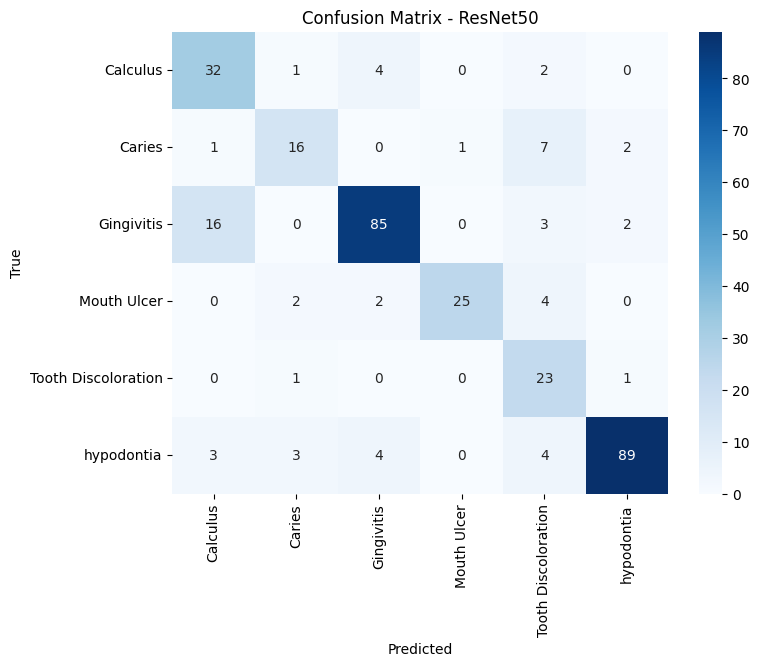

In [47]:
y_pred_probs_resnet = resnet_model.predict(test_ds)
y_pred_resnet = np.argmax(y_pred_probs_resnet, axis=1)

print(classification_report(y_true, y_pred_resnet, target_names=class_names))

cm_resnet = confusion_matrix(y_true, y_pred_resnet)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_resnet, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - ResNet50")
plt.show()

## 11. Pretrained Model 3: MobileNetV2

### 11.1 Build the Model (Feature Extraction)

In [49]:
base_model_mobilenet = MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
    pooling="avg",
)
base_model_mobilenet.trainable = False

inputs = keras.Input(shape=(224, 224, 3), name="input_image")
x = Augmentation(inputs)
x = layers.Lambda(mobilenet_preprocess, name="mobilenet_preprocess")(x)
x = base_model_mobilenet(x, training=False)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

mobilenet_model = keras.Model(inputs, outputs, name="mobilenetv2_transfer")
mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ img_augmentation (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess (Lambda)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 11.2 Compile the Model

In [50]:
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

### 11.3 Training Callbacks

In [51]:
early_stop_mobilenet = EarlyStopping(monitor="val_accuracy", patience=7, restore_best_weights=True)
reduce_lr_mobilenet = ReduceLROnPlateau(monitor="val_accuracy", factor=0.5, patience=3, min_lr=1e-6)
ckpt_mobilenet = ModelCheckpoint("mobilenetv2_model.keras", save_best_only=True, monitor="val_accuracy", mode="max")

callbacks_mobilenet = [early_stop_mobilenet, ckpt_mobilenet, reduce_lr_mobilenet]

### 11.4 Train the Model

In [52]:
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_TL,
    class_weight=class_weights,
    callbacks=callbacks_mobilenet,
)

Epoch 1/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 10s 115ms/step - accuracy: 0.4398 - loss: 1.5665 - val_accuracy: 0.6006 - val_loss: 1.0209 - learning_rate: 0.0010
Epoch 2/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.6349 - loss: 1.0348 - val_accuracy: 0.6967 - val_loss: 0.8337 - learning_rate: 0.0010
Epoch 3/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 80ms/step - accuracy: 0.6890 - loss: 0.8889 - val_accuracy: 0.7027 - val_loss: 0.7813 - learning_rate: 0.0010
Epoch 4/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.7057 - loss: 0.8097 - val_accuracy: 0.7327 - val_loss: 0.7140 - learning_rate: 0.0010
Epoch 5/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.7457 - loss: 0.7023 - val_accuracy: 0.7417 - val_loss: 0.6898 - learning_rate: 0.0010
Epoch 6/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.7431 - loss: 0.7030 - val_accuracy: 0.7477 - val_loss: 0.6915 - learning_rate: 0.0010
Epoch 7/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.7579 - loss: 0.6612 - val_a

### 11.5 Training History Curves

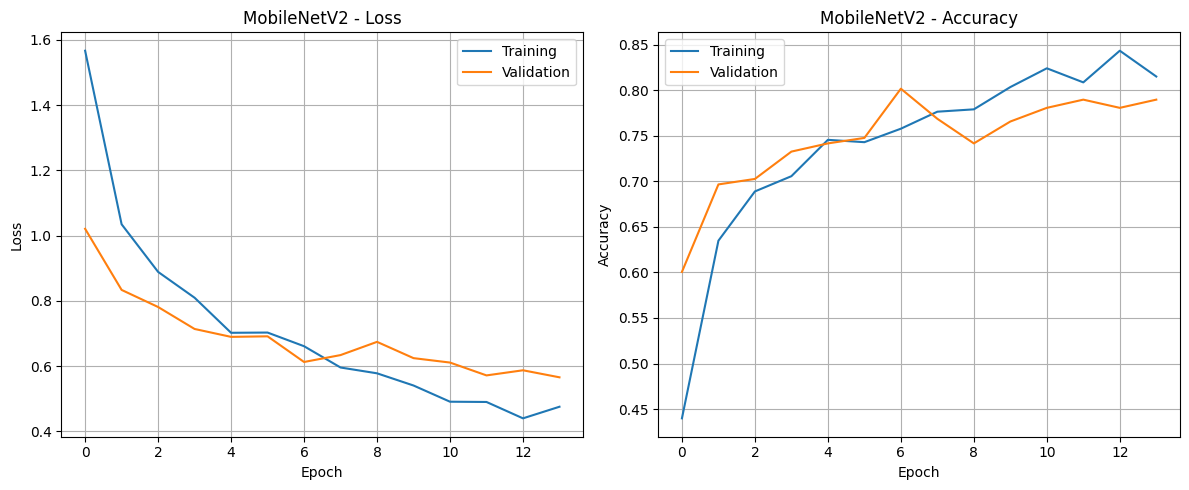

In [53]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_mobilenet.history['loss'], label='Training')
plt.plot(history_mobilenet.history['val_loss'], label='Validation')
plt.title('MobileNetV2 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_mobilenet.history['accuracy'], label='Training')
plt.plot(history_mobilenet.history['val_accuracy'], label='Validation')
plt.title('MobileNetV2 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 11.6 Evaluation on the Test Set

In [54]:
test_loss_mobilenet, test_acc_mobilenet = mobilenet_model.evaluate(test_ds)
print(f"MobileNetV2 - Test accuracy: {test_acc_mobilenet:.4f}")
print(f"MobileNetV2 - Test loss: {test_loss_mobilenet:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.7688 - loss: 0.6550
MobileNetV2 - Test accuracy: 0.7688
MobileNetV2 - Test loss: 0.6550


### 11.7 Classification Report and Confusion Matrix

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step
                     precision    recall  f1-score   support

           Calculus       0.70      0.54      0.61        39
             Caries       0.53      0.63      0.58        27
         Gingivitis       0.73      0.92      0.82       106
        Mouth Ulcer       0.86      0.76      0.81        33
Tooth Discoloration       0.61      0.76      0.68        25
         hypodontia       0.97      0.75      0.85       103

           accuracy                           0.77       333
          macro avg       0.74      0.72      0.72       333
       weighted avg       0.79      0.77      0.77       333



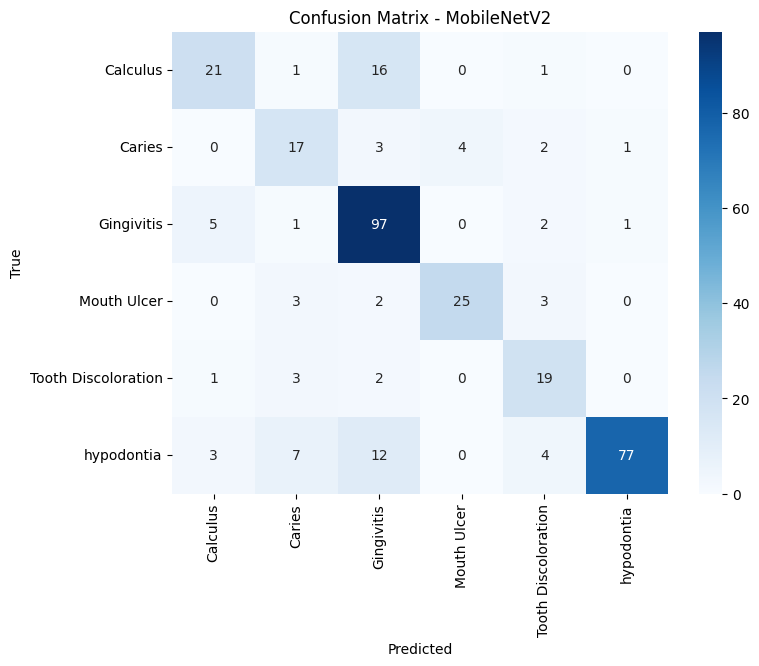

In [55]:
y_pred_probs_mobilenet = mobilenet_model.predict(test_ds)
y_pred_mobilenet = np.argmax(y_pred_probs_mobilenet, axis=1)

print(classification_report(y_true, y_pred_mobilenet, target_names=class_names))

cm_mobilenet = confusion_matrix(y_true, y_pred_mobilenet)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_mobilenet, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - MobileNetV2")
plt.show()

## 12. Model Comparison

### 12.1 Test Accuracy Comparison

            Model  Test Accuracy  Test Loss
0      Custom CNN       0.714715   0.772243
1  EfficientNetB2       0.795796   0.610384
2        ResNet50       0.810811   0.505175
3     MobileNetV2       0.768769   0.654991


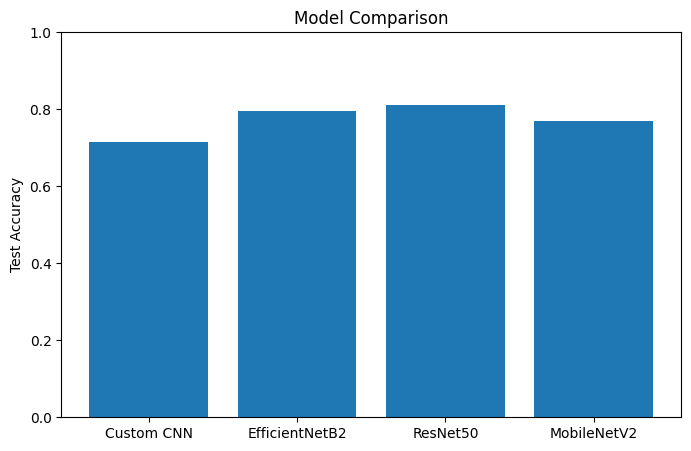

In [56]:
results = pd.DataFrame({
    "Model": ["Custom CNN", "EfficientNetB2", "ResNet50", "MobileNetV2"],
    "Test Accuracy": [test_acc, test_acc_effnet, test_acc_resnet, test_acc_mobilenet],
    "Test Loss": [test_loss, test_loss_effnet, test_loss_resnet, test_loss_mobilenet],
})
print(results)

plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["Test Accuracy"])
plt.ylabel("Test Accuracy")
plt.title("Model Comparison")
plt.ylim(0, 1)
plt.show()